<a href="https://colab.research.google.com/github/santana-robledo/Posgrado_Robotica_e_Inteligencia_Artificial/blob/main/Vision_Artificial/04.%20IdentificacionFacialChallenge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Librerías para visión artificial
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
cv2.data.haarcascades

'/usr/local/lib/python3.12/dist-packages/cv2/data/'

In [ ]:
ls '/usr/local/lib/python3.12/dist-packages/cv2/data/'

haarcascade_eye_tree_eyeglasses.xml
haarcascade_eye.xml
haarcascade_frontalcatface_extended.xml
haarcascade_frontalcatface.xml
haarcascade_frontalface_alt2.xml
haarcascade_frontalface_alt_tree.xml
haarcascade_frontalface_alt.xml
haarcascade_frontalface_default.xml
haarcascade_fullbody.xml
haarcascade_lefteye_2splits.xml
haarcascade_license_plate_rus_16stages.xml
haarcascade_lowerbody.xml
haarcascade_profileface.xml
haarcascade_righteye_2splits.xml
haarcascade_russian_plate_number.xml
haarcascade_smile.xml
haarcascade_upperbody.xml
__init__.py
__pycache__/


In [ ]:
# Cargando el modelo preentrenado
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_alt.xml")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


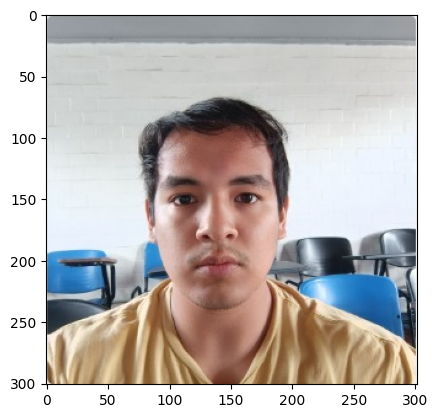

In [ ]:
# Lectura de la imagen
ruta = "/content/drive/MyDrive/IdentificacionFacial_V19/"
img = cv2.imread(ruta + "JosueSantana_2.jpeg")
# Conversión de formato
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img, cmap = "Accent")
plt.show()

## Reto 1: Colocar el cuadro delimitador del rostro

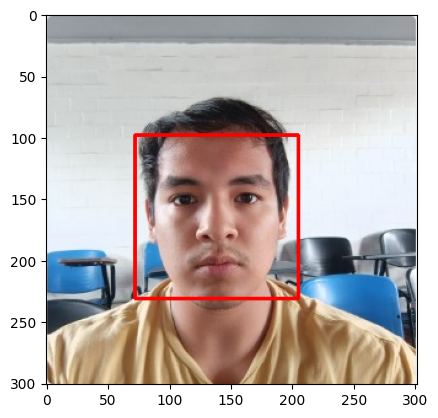

In [ ]:
img_copy=img.copy()
for (x,y,w,h) in rostros:
  cv2.rectangle(img_copy,(x,y),(x+w,y+h),(255,0,0),thickness=2)
plt.imshow(img_copy, cmap = "Accent")
plt.show()

## Creación de datos de entrenamiento

In [ ]:
import cv2

face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

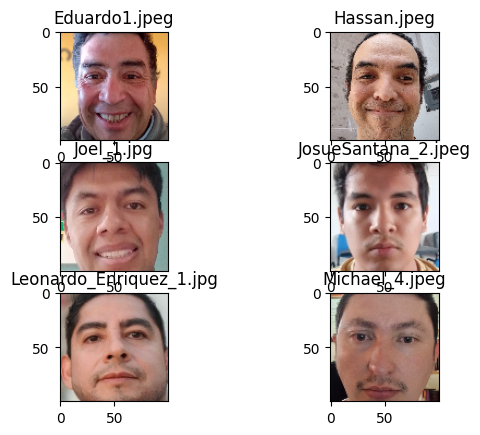

In [ ]:
# Base de entrenamiento con 1 imágen por persona a color
imagenes = [ "Eduardo1.jpeg","Hassan.jpeg","Joel_1.jpg","JosueSantana_2.jpeg","Leonardo_Enriquez_1.jpg","Michael_4.jpeg"]
etiquetas = [0,1,2,3,4,5]
x_train = []
y_train =[]
# Deteccion de rostros
for i in range( len(imagenes)):
  img = cv2.imread( ruta+ imagenes[i])
  img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  rostros = face_cascade.detectMultiScale(img,scaleFactor=1.2, minNeighbors=3)
  if len(rostros) > 0:
    x, y, w, h = rostros[0]
    rostro = img[y:y+h, x:x+w, :]
    rostro = cv2.resize(rostro, (100,100))
    # Adjuntamos imágen y etiqueta
    x_train.append(rostro)
    y_train.append(etiquetas[i])
    # Mostramos las imágenes


    plt.subplot(3,2,i+1)
    plt.imshow(rostro, cmap = 'Accent')
    plt.title(imagenes[i])
plt.show()

In [ ]:
# Convertimos a arreglos
import numpy as np
x_train = np.array(x_train)
y_train = np.array(y_train)

In [ ]:
print(x_train.shape)

(6, 100, 100, 3)


In [ ]:
# Aplanamos las imágenes
x_train = x_train.reshape(6,30000)

In [ ]:
x_train = x_train/255

## Creación del modelo

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

In [ ]:
# Construcción del clasificador
clasificador = KNeighborsClassifier(n_neighbors=1)
clasificador.fit(x_train, y_train)

KNeighborsClassifier(n_neighbors=1)

In [ ]:
imagenes2 = [ "Eduardo2.jpeg","Hassan2.jpeg","Joel_2.jpg","JosueSantana_1.jpeg","Leonardo_Enriquez_2.jpg","Michael_5.jpeg"]


[[101 297 850 850]]


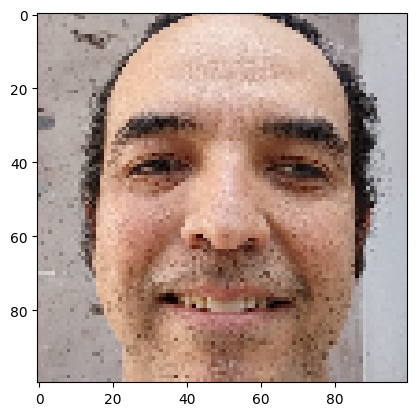

In [ ]:
# Prueba del modelo
imgTest = cv2.imread(ruta+ imagenes2[1] )
# Conversión de formato
imgTest = cv2.cvtColor(imgTest, cv2.COLOR_BGR2RGB)
# Detección de rostros
rostro = face_cascade.detectMultiScale(imgTest,1.2, 1)
print(rostro)
# Selección del rostro
for (x, y, w, h) in rostro:
  rostroTest = imgTest[y:y+h, x:x+w, :]
  rostroTest = cv2.resize(rostroTest, (100,100))
  break
plt.imshow(rostroTest, cmap = 'Accent')
plt.show()


In [ ]:
# Clasificación
rostroTestPre = rostroTest.reshape(1,30000)
rostroTest = rostroTest/255
persona= clasificador.predict(rostroTestPre)
print(imagenes[persona[0]])

Hassan.jpeg
